# Step 1: Install and Import Libraries

In [1]:
!pip install pandas prophet requests numpy -q

In [2]:
# Get time series data
#import yfinance as yf

# Prophet model for time series forecast
from prophet import Prophet

# Data processing
import numpy as np
import pandas as pd

import requests
import json
from datetime import datetime

# Step 2: Pull Data

In [3]:
f = open("shipping_responsetime.json")
prom = json.load(f)
prom

{'status': 'success',
 'data': {'resultType': 'matrix',
  'result': [{'metric': {},
    'values': [[1791533370, '3.8571022177067285'],
     [1791533400, '4.349999999999994'],
     [1791533430, '4.239999999999997'],
     [1791533460, '3.8571428571428545'],
     [1791533490, '3.2499999999999964'],
     [1791533520, '3.5333333333333314'],
     [1791533550, '0.9965909090909091'],
     [1791533580, '3.449999999999996'],
     [1791533610, '3.849999999999999'],
     [1791533640, '3.066639999999998'],
     [1791533670, '2.0000000000000053'],
     [1791533700, '3.9142857142857124'],
     [1791533730, '3.942860408266929'],
     [1791533760, '2.800000000000001'],
     [1791533790, '2.6666666666666643'],
     [1791533820, '4.114285714285712'],
     [1791533850, '4.085724443992966'],
     [1791533880, '5.749999999999998'],
     [1791533910, '5.999999999999997'],
     [1791533940, '3.8999999999999986'],
     [1791533970, '3.8800000000000003'],
     [1791534000, '3.759999999999999'],
     [1791534030

In [4]:
df_train = pd.DataFrame( prom['data']['result'][0]['values'] )
df_train.columns = ['ds', 'y']
df_train.info()
df_train

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   ds      1440 non-null   int64
 1   y       1440 non-null   str  
dtypes: int64(1), str(1)
memory usage: 22.6 KB


,ds,y
0,1791533370,3.8571022177067285
1,1791533400,4.349999999999994
2,1791533430,4.239999999999997
3,1791533460,3.8571428571428545
4,1791533490,3.2499999999999964
...,...,...
1435,1791576420,1.5999999999999983
1436,1791576450,3.5499975000416653
1437,1791576480,4.039999999999999
1438,1791576510,6.624966666666664


In [5]:
df_train['ds'] = df_train['ds'].apply(lambda sec: datetime.fromtimestamp(sec))
df_train['y']= df_train['y'].astype(float)
df_train.info()
df_train

<class 'pandas.DataFrame'>
RangeIndex: 1440 entries, 0 to 1439
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   ds      1440 non-null   datetime64[us]
 1   y       1440 non-null   float64       
dtypes: datetime64[us](1), float64(1)
memory usage: 22.6 KB


,ds,y
0,2026-10-09 08:09:30,3.857102
1,2026-10-09 08:10:00,4.350000
2,2026-10-09 08:10:30,4.240000
3,2026-10-09 08:11:00,3.857143
4,2026-10-09 08:11:30,3.250000
...,...,...
1435,2026-10-09 20:07:00,1.600000
1436,2026-10-09 20:07:30,3.549998
1437,2026-10-09 20:08:00,4.040000
1438,2026-10-09 20:08:30,6.624967


Next, let's visualize the closing prices of the two tickers using `seaborn`, and add the legend to the plot using `matplotlib`. We can see that the price for Google increased a lot starting in late 2020, and almost doubled in late 2021.

<Axes: xlabel='ds'>

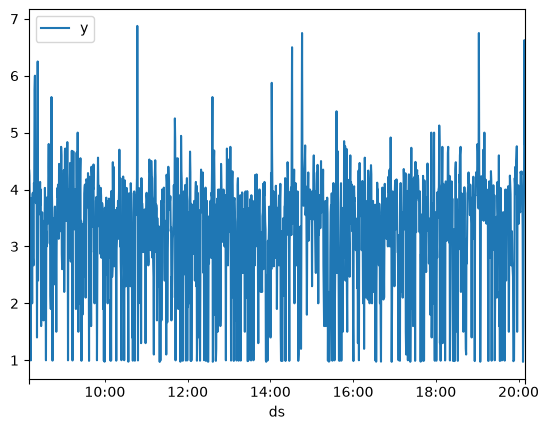

In [6]:
df_train.plot(x="ds", y="y")

In [8]:
url_test_data = {
    "query": "histogram_quantile( 0.95, sum by (le) (increase(istio_request_duration_milliseconds_bucket{destination_canonical_service='shippingservice', reporter='source'}[1m])))[1h:30s]"
    }
test_url = "http://localhost:9090/api/v1/query"

r = requests.get(test_url, params=url_test_data)
prom = r.json()
print(prom)

{'status': 'success', 'data': {'resultType': 'matrix', 'result': [{'metric': {}, 'values': [[1791610950, '3.7999999999999985'], [1791610980, '4.199999999999999'], [1791611010, '3.800026666666663'], [1791611040, '2.3999999999999964'], [1791611070, '0.9916666666666665'], [1791611100, '3.6799978666287405'], [1791611130, '3.8857142857142852'], [1791611160, '3.3666666666666636'], [1791611190, '3.1999999999999926'], [1791611220, '3.333357034930227'], [1791611250, '2.0999644428641293'], [1791611280, '3.7499999999999996'], [1791611310, '2.849999999999998'], [1791611340, '0.9896551724137932'], [1791611370, '2.0999999999999996'], [1791611400, '3.7714285714285714'], [1791611430, '1.4999999999999933'], [1791611460, '1'], [1791611490, '1.7999999999999978'], [1791611520, '3.2999999999999994'], [1791611550, '0.98828125'], [1791611580, '3.4000000000000012'], [1791611610, '3.6999999999999993'], [1791611640, '4.199999999999994'], [1791611670, '4.299999999999997'], [1791611700, '2.0999999999999917'], [17

In [9]:
result =  prom['data']['result']
result



[{'metric': {},
  'values': [[1791610950, '3.7999999999999985'],
   [1791610980, '4.199999999999999'],
   [1791611010, '3.800026666666663'],
   [1791611040, '2.3999999999999964'],
   [1791611070, '0.9916666666666665'],
   [1791611100, '3.6799978666287405'],
   [1791611130, '3.8857142857142852'],
   [1791611160, '3.3666666666666636'],
   [1791611190, '3.1999999999999926'],
   [1791611220, '3.333357034930227'],
   [1791611250, '2.0999644428641293'],
   [1791611280, '3.7499999999999996'],
   [1791611310, '2.849999999999998'],
   [1791611340, '0.9896551724137932'],
   [1791611370, '2.0999999999999996'],
   [1791611400, '3.7714285714285714'],
   [1791611430, '1.4999999999999933'],
   [1791611460, '1'],
   [1791611490, '1.7999999999999978'],
   [1791611520, '3.2999999999999994'],
   [1791611550, '0.98828125'],
   [1791611580, '3.4000000000000012'],
   [1791611610, '3.6999999999999993'],
   [1791611640, '4.199999999999994'],
   [1791611670, '4.299999999999997'],
   [1791611700, '2.09999999999

In [16]:
df = pd.DataFrame(columns=['ds', 'y'])
time = result[0]['values']
val = result[0]['values']
df.info()
print(time)
print(val)

<class 'pandas.DataFrame'>
RangeIndex: 0 entries
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   ds      0 non-null      object
 1   y       0 non-null      object
dtypes: object(2)
memory usage: 132.0+ bytes
[[1791610950, '3.7999999999999985'], [1791610980, '4.199999999999999'], [1791611010, '3.800026666666663'], [1791611040, '2.3999999999999964'], [1791611070, '0.9916666666666665'], [1791611100, '3.6799978666287405'], [1791611130, '3.8857142857142852'], [1791611160, '3.3666666666666636'], [1791611190, '3.1999999999999926'], [1791611220, '3.333357034930227'], [1791611250, '2.0999644428641293'], [1791611280, '3.7499999999999996'], [1791611310, '2.849999999999998'], [1791611340, '0.9896551724137932'], [1791611370, '2.0999999999999996'], [1791611400, '3.7714285714285714'], [1791611430, '1.4999999999999933'], [1791611460, '1'], [1791611490, '1.7999999999999978'], [1791611520, '3.2999999999999994'], [1791611550, '0.98828125'], [1

In [17]:
df.shape

(0, 2)

In [19]:
new_row = {'ds': time, 'y': val}
df.loc[0] = new_row
# time and val are lists like [timestamp, value]; use the scalar parts only
df = pd.DataFrame({
    'ds': [item[0] for item in time],
    'y': [float(item[1]) for item in val]
})
df['y'] = df['y'].astype(float)
df['ds'] = df['ds'].apply(lambda sec: datetime.fromtimestamp(sec))
df

,ds,y
0,2026-10-10 05:42:30,3.800000
1,2026-10-10 05:43:00,4.200000
2,2026-10-10 05:43:30,3.800027
3,2026-10-10 05:44:00,2.400000
4,2026-10-10 05:44:30,0.991667
...,...,...
115,2026-10-10 06:40:00,1.500000
116,2026-10-10 06:40:30,3.750000
117,2026-10-10 06:41:00,3.850000
118,2026-10-10 06:41:30,3.066667


# Step 3: Build Time Series Model Using Prophet in Python

In [28]:
# Add seasonality
model = Prophet(interval_width=0.95, growth='flat', yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=True)

# Fit the model on the training dataset
model.fit(df_train)

Yearly seasonality is enabled with less than 730 days (approximately 2 years) of history. The model may be under-identified, and the trend/seasonality decomposition can be unstable and dependent on the Prophet/Stan version. Consider disabling yearly seasonality or providing more history.
06:48:26 - cmdstanpy - INFO - Chain [1] start processing
06:48:26 - cmdstanpy - INFO - Chain [1] done processing


# Step 4: Make Predictions Using Prophet in Python

After building the model, in step 4, we use the model to make predictions on the dataset. The forecast plot shows that the predictions are in general aligned with the actual values.

In [29]:
# Make prediction
forecast = model.predict(df)

# Step 5: Check Time Series Model Performace

In [30]:
forecast

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,daily,...,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2026-10-10 05:42:30,3.255614,2.027057,6.005344,3.255614,3.255614,0.696836,0.696836,0.696836,1.183976,...,-0.626033,-0.626033,-0.626033,0.138893,0.138893,0.138893,0.0,0.0,0.0,3.952450
1,2026-10-10 05:43:00,3.255614,1.756212,5.921113,3.255614,3.255614,0.691492,0.691492,0.691492,1.178641,...,-0.626036,-0.626036,-0.626036,0.138887,0.138887,0.138887,0.0,0.0,0.0,3.947106
2,2026-10-10 05:43:30,3.255614,1.992566,5.975361,3.255614,3.255614,0.686134,0.686134,0.686134,1.173292,...,-0.626039,-0.626039,-0.626039,0.138881,0.138881,0.138881,0.0,0.0,0.0,3.941748
3,2026-10-10 05:44:00,3.255614,1.918032,5.901055,3.255614,3.255614,0.680762,0.680762,0.680762,1.167928,...,-0.626041,-0.626041,-0.626041,0.138875,0.138875,0.138875,0.0,0.0,0.0,3.936376
4,2026-10-10 05:44:30,3.255614,1.916097,5.930183,3.255614,3.255614,0.675377,0.675377,0.675377,1.162551,...,-0.626043,-0.626043,-0.626043,0.138869,0.138869,0.138869,0.0,0.0,0.0,3.930991
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
115,2026-10-10 06:40:00,3.255614,1.444244,5.230446,3.255614,3.255614,0.053845,0.053845,0.053845,0.539543,...,-0.623874,-0.623874,-0.623874,0.138177,0.138177,0.138177,0.0,0.0,0.0,3.309459
116,2026-10-10 06:40:30,3.255614,1.314974,5.177866,3.255614,3.255614,0.048521,0.048521,0.048521,0.534183,...,-0.623833,-0.623833,-0.623833,0.138170,0.138170,0.138170,0.0,0.0,0.0,3.304134
117,2026-10-10 06:41:00,3.255614,1.372186,5.220018,3.255614,3.255614,0.043208,0.043208,0.043208,0.528836,...,-0.623792,-0.623792,-0.623792,0.138164,0.138164,0.138164,0.0,0.0,0.0,3.298822
118,2026-10-10 06:41:30,3.255614,1.205113,5.279994,3.255614,3.255614,0.037908,0.037908,0.037908,0.523501,...,-0.623750,-0.623750,-0.623750,0.138158,0.138158,0.138158,0.0,0.0,0.0,3.293522


In [31]:
# Merge actual and predicted values
performance = pd.merge(df, forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']], on='ds')

In [32]:
performance

,ds,y,yhat,yhat_lower,yhat_upper
0,2026-10-10 05:42:30,3.800000,3.952450,2.027057,6.005344
1,2026-10-10 05:43:00,4.200000,3.947106,1.756212,5.921113
2,2026-10-10 05:43:30,3.800027,3.941748,1.992566,5.975361
3,2026-10-10 05:44:00,2.400000,3.936376,1.918032,5.901055
4,2026-10-10 05:44:30,0.991667,3.930991,1.916097,5.930183
...,...,...,...,...,...
115,2026-10-10 06:40:00,1.500000,3.309459,1.444244,5.230446
116,2026-10-10 06:40:30,3.750000,3.304134,1.314974,5.177866
117,2026-10-10 06:41:00,3.850000,3.298822,1.372186,5.220018
118,2026-10-10 06:41:30,3.066667,3.293522,1.205113,5.279994


# Step 6: Identify Anomalies

In step 6, we will identify the time series anomalies by checking if the actual value is outside of the uncertainty interval. If the actual value is smaller than the lower bound or larger than the upper bound of the uncertainty interval, the anomaly indicator is set to 1, otherwise, it's set to 0.

Using `value_counts()`, we can see that there are 6 outliers out of 505 data points.

In [33]:
# Create an anomaly indicator
performance['anomaly'] = performance.apply(lambda rows: 1 if ((float(rows.y)>rows.yhat_upper)) else 0, axis = 1)


In [34]:
performance.info()

<class 'pandas.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   ds          120 non-null    datetime64[us]
 1   y           120 non-null    float64       
 2   yhat        120 non-null    float64       
 3   yhat_lower  120 non-null    float64       
 4   yhat_upper  120 non-null    float64       
 5   anomaly     120 non-null    int64         
dtypes: datetime64[us](1), float64(4), int64(1)
memory usage: 5.8 KB


In [35]:
# Check the number of anomalies
performance['anomaly'].value_counts()
performance

,ds,y,yhat,yhat_lower,yhat_upper,anomaly
0,2026-10-10 05:42:30,3.800000,3.952450,2.027057,6.005344,0
1,2026-10-10 05:43:00,4.200000,3.947106,1.756212,5.921113,0
2,2026-10-10 05:43:30,3.800027,3.941748,1.992566,5.975361,0
3,2026-10-10 05:44:00,2.400000,3.936376,1.918032,5.901055,0
4,2026-10-10 05:44:30,0.991667,3.930991,1.916097,5.930183,0
...,...,...,...,...,...,...
115,2026-10-10 06:40:00,1.500000,3.309459,1.444244,5.230446,0
116,2026-10-10 06:40:30,3.750000,3.304134,1.314974,5.177866,0
117,2026-10-10 06:41:00,3.850000,3.298822,1.372186,5.220018,0
118,2026-10-10 06:41:30,3.066667,3.293522,1.205113,5.279994,0


After printing out the anomalies, we can see that all the outliers are lower than the lower bound of the uncertainty interval.

In [36]:
# Take a look at the anomalies
anomalies = performance[performance['anomaly']==1].sort_values(by='ds')
anomalies

,ds,y,yhat,yhat_lower,yhat_upper,anomaly
